## Nome: Mayara Cristina
## Matricula: 574

## Atividade 13 – Análise dos Tempos de Resposta em uma Rede de Sensores Industriais

Uma equipe de engenharia está avaliando o desempenho de uma rede de sensores utilizada para monitorar variáveis de uma planta industrial. Nesse sistema, módulos embarcados enviam informações para uma estação central, que confirma o recebimento de cada mensagem.

Durante os ensaios, foram avaliados **20 módulos de telemetria** sob condições de teste semelhantes. Para cada módulo, a equipe registrou a **latência média de comunicação (em milissegundos)**, isto é, o tempo médio entre o envio de uma mensagem e a confirmação de seu recebimento. Os dados são **simulados para fins didáticos**.

A equipe deseja compreender o comportamento típico da comunicação e identificar possíveis diferenças de desempenho entre os módulos. Como referência do projeto, considera-se desejável uma latência média de até **130 ms** por módulo. Tempos elevados podem afetar a atualização das informações de monitoramento, mas conclusões sobre suas causas exigem investigação técnica adicional.

Utilize os dados da tabela a seguir para realizar as análises estatísticas propostas:

| Módulo de Telemetria | Latência Média (ms) |
|---------------------|--------------------|
| Módulo 01           | 104                |
| Módulo 02           | 111                |
| Módulo 03           | 116                |
| Módulo 04           | 109                |
| Módulo 05           | 113                |
| Módulo 06           | 76                 |
| Módulo 07           | 129                |
| Módulo 08           | 110                |
| Módulo 09           | 115                |
| Módulo 10           | 121                |
| Módulo 11           | 83                 |
| Módulo 12           | 182                |
| Módulo 13           | 108                |
| Módulo 14           | 93                 |
| Módulo 15           | 116                |
| Módulo 16           | 107                |
| Módulo 17           | 88                 |
| Módulo 18           | 112                |
| Módulo 19           | 119                |
| Módulo 20           | 125                |


In [1]:
# Bibliotecas para visualização dos resultados
import seaborn as sns
import matplotlib.pyplot as plt

# Bibliotecas para análise estatística das medições
import numpy as np
import pandas as pd

In [2]:
# Dados simulados dos ensaios de latência dos módulos de telemetria
# Cada valor representa a latência média registrada para um módulo, em ms.
tabela = {
    "Módulo de Telemetria": [
        "Módulo 01", "Módulo 02", "Módulo 03", "Módulo 04", "Módulo 05",
        "Módulo 06", "Módulo 07", "Módulo 08", "Módulo 09", "Módulo 10",
        "Módulo 11", "Módulo 12", "Módulo 13", "Módulo 14", "Módulo 15",
        "Módulo 16", "Módulo 17", "Módulo 18", "Módulo 19", "Módulo 20"
    ],
    "Latência Média (ms)": [
        104, 111, 116, 109, 113, 76, 129, 110, 115, 121,
        83, 182, 108, 93, 116, 107, 88, 112, 119, 125
    ]
}

dados = pd.DataFrame(tabela)
display(dados)

,Módulo de Telemetria,Latência Média (ms)
0,Módulo 01,104
1,Módulo 02,111
2,Módulo 03,116
3,Módulo 04,109
4,Módulo 05,113
5,Módulo 06,76
6,Módulo 07,129
7,Módulo 08,110
8,Módulo 09,115
9,Módulo 10,121


---
### Parte 1 - Tendência Central e Interpretação

Obs.: Se necessário, ordene os valores de latência em ordem crescente ou decrescente (rol).

In [5]:
# Ordenar os módulos por latência média de comunicação (crescente)
df_ordenado = dados.sort_values(by='Latência Média (ms)', ascending=True).reset_index(drop=True)

# Média das latências medidas
media = dados['Latência Média (ms)'].mean()

# Mediana das latências medidas
mediana = dados['Latência Média (ms)'].median()

# Moda das latências (a série pode apresentar mais de uma moda)
moda = dados['Latência Média (ms)'].mode()

display(df_ordenado)

,Módulo de Telemetria,Latência Média (ms)
0,Módulo 06,76
1,Módulo 11,83
2,Módulo 17,88
3,Módulo 14,93
4,Módulo 01,104
5,Módulo 16,107
6,Módulo 13,108
7,Módulo 04,109
8,Módulo 08,110
9,Módulo 02,111


1. Calcule a média, a mediana e a moda dos tempos médios de resposta dos 20 módulos de telemetria. Apresente os resultados em milissegundos (ms).
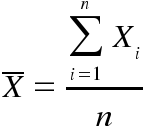
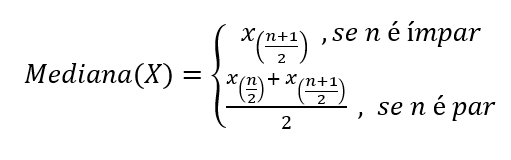


In [4]:
print(f"Média: {media:.2f} ms")
print(f"Mediana: {mediana:.2f} ms")
print(f"Moda: {moda.iloc[0]} ms")

Média: 111.85 ms
Mediana: 111.50 ms
Moda: 116 ms


2. Os valores obtidos para média, mediana e moda são próximos? Qual dessas medidas representa melhor o desempenho típico de comunicação dos módulos analisados? Justifique com base nos resultados.

*Resposta*: Sim, os valores são próximos. A mediana, de 111,50 ms, representa melhor o desempenho típico porque sofre menos influência dos valores extremos, como os 182 ms do Módulo 12. A proximidade entre média e mediana indica que ambas descrevem um valor central semelhante.

3. Identifique os módulos cujas latências estão mais distantes da média do conjunto. O que esses resultados podem indicar sobre o desempenho dos módulos e quais fatores técnicos poderiam ser investigados?

Resposta: O Módulo 12 apresenta comunicação mais lenta, enquanto os demais apresentam comunicação mais rápida que a média. Podem ser investigados fatores como intensidade do sinal, interferências, distância da estação central, retransmissões, configuração e processamento dos dispositivos. Os dados, sozinhos, não permitem determinar a causa dessas diferenças.

---
### Parte 2 – Separatrizes (Quartis)

In [6]:
# Cálculo dos quartis das latências médias de comunicação
quartis = dados['Latência Média (ms)'].quantile([0.25, 0.5, 0.75])

4. Calcule os quartis Q1, Q2 (mediana) e Q3 das latências médias dos módulos. Apresente os valores em milissegundos (ms).
<br>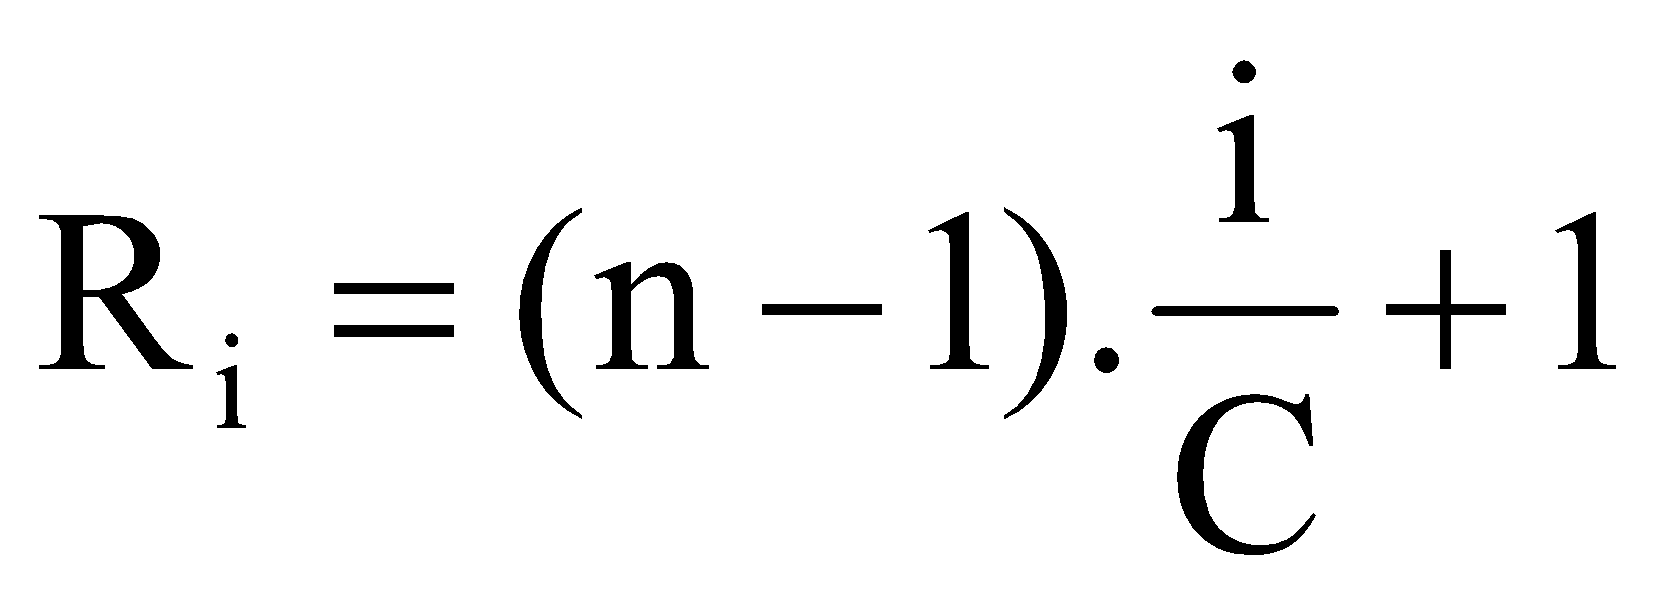

In [7]:
print(f"Q1: {quartis.loc[0.25]:.2f} ms")
print(f"Q2: {quartis.loc[0.5]:.2f} ms")
print(f"Q3: {quartis.loc[0.75]:.2f} ms")

Q1: 106.25 ms
Q2: 111.50 ms
Q3: 116.75 ms


5. Quais módulos apresentam latências abaixo de Q1? O que esse resultado representa em termos de rapidez de comunicação?

Resposta: Os módulos abaixo de 106,25 ms são: Módulo 06 (76 ms), Módulo 11 (83 ms), Módulo 17 (88 ms), Módulo 14 (93 ms) e Módulo 01 (104 ms). Eles correspondem aos 25% dos módulos com menores latências, apresentando comunicação mais rápida nas condições avaliadas.

6. Quais módulos apresentam latências acima de Q3? Explique por que esses módulos podem exigir uma análise adicional do sistema de comunicação.

Resposta: Os módulos acima de 116,75 ms são: Módulo 19 (119 ms), Módulo 10 (121 ms), Módulo 20 (125 ms), Módulo 07 (129 ms) e Módulo 12 (182 ms). Eles estão entre os 25% com maiores latências. Merecem análise adicional para verificar possíveis atrasos, principalmente o Módulo 12, que ultrapassa a referência de 130 ms.

---
### Parte 3 – Dispersão

In [8]:
# Amplitude das latências: maior valor menos menor valor (ms)
latencias = dados['Latência Média (ms)']
amplitude = max(latencias) - min(latencias)

# Função para calcular a variância amostral das latências (ms²)
def variancia_latencia(valores):
    media = sum(valores) / len(valores)
    return sum((x - media) ** 2 for x in valores) / (len(valores) - 1)

# Função para calcular o desvio-padrão amostral das latências (ms)
def desvio_padrao_latencia(valores):
    return variancia_latencia(valores) ** 0.5

7. Calcule as seguintes medidas de dispersão para as latências médias dos módulos:

- Amplitude (ms):
<br>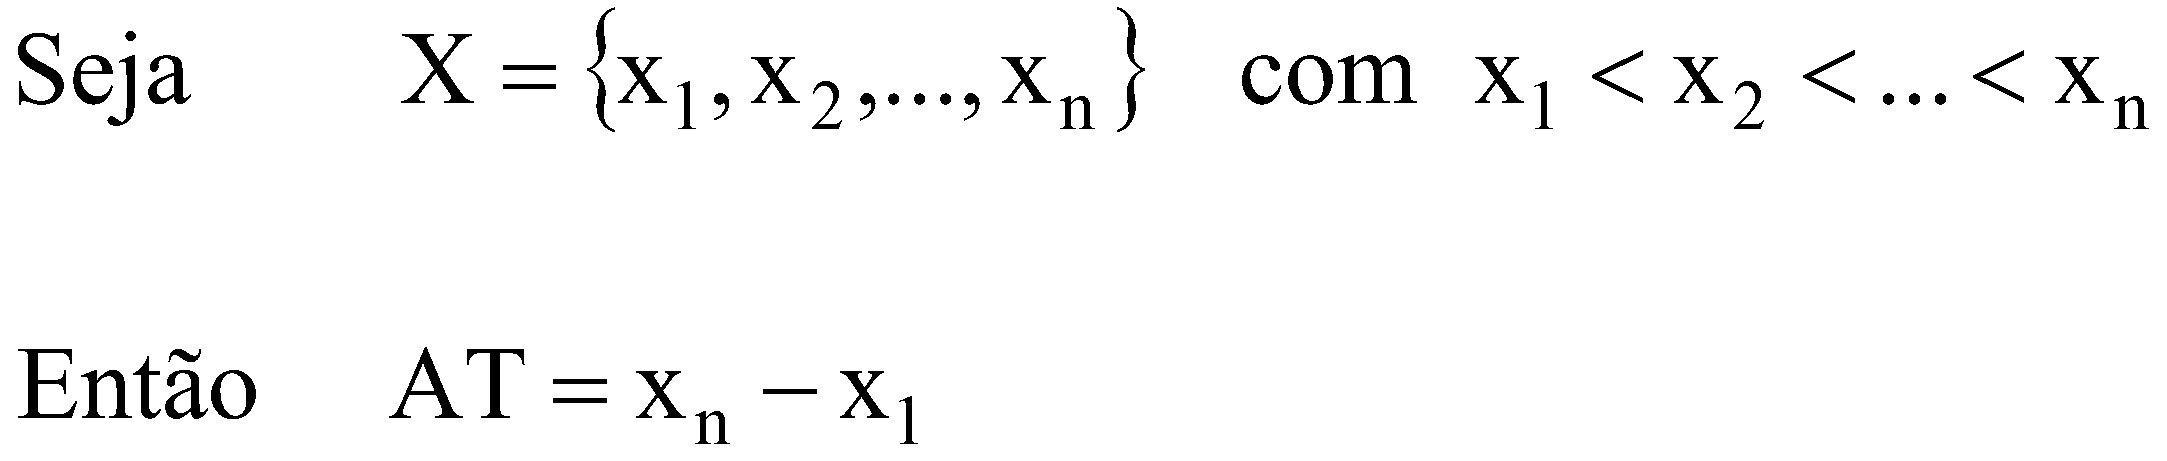

In [9]:
print(f"Amplitude: {amplitude:.2f} ms")

Amplitude: 106.00 ms


- Variância (amostral, em ms²):
<br>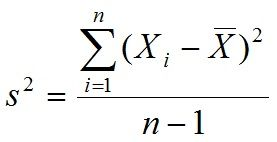

In [10]:
print(f"Variância amostral: {variancia_latencia(latencias):.2f} ms²")

Variância amostral: 459.08 ms²


- Desvio Padrão (amostral, em ms):
<br>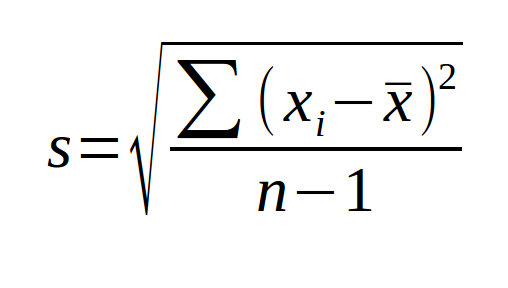


In [11]:
print(f"Desvio padrão amostral: {desvio_padrao_latencia(latencias):.2f} ms")

Desvio padrão amostral: 21.43 ms


8. As latências variam muito entre os módulos? Como essa dispersão pode influenciar a escolha de dispositivos, o diagnóstico de falhas e a confiabilidade do monitoramento industrial? Justifique com base nas medidas calculadas.

Resposta: Há diferenças relevantes entre os módulos: a amplitude é de 106 ms e o desvio padrão amostral é de 21,43 ms. Entretanto, a metade central dos valores está entre 106,25 e 116,75 ms, mostrando que boa parte dos módulos apresenta latências próximas. Os extremos aumentam a dispersão e devem ser investigados. Na escolha dos dispositivos, convém considerar a latência e a regularidade da comunicação, pois atrasos elevados podem prejudicar a atualização das informações e a confiabilidade do monitoramento.

---
### Parte 4 – Visualização de Dados

In [12]:
# Função para visualizar a distribuição das latências por histograma
def plot_histograma_latencia(dados, coluna='Latência Média (ms)', bins=10):
    """
    Plota um histograma das latências registradas nos módulos.
    :param dados: DataFrame com os resultados dos ensaios
    :param coluna: Nome da coluna de latências, em milissegundos
    :param bins: Número de intervalos do histograma
    """
    plt.figure(figsize=(8, 5))
    plt.hist(dados[coluna], bins=bins, color='skyblue', edgecolor='black')
    plt.title('Distribuição das latências dos módulos de telemetria')
    plt.xlabel('Latência média de comunicação (ms)')
    plt.ylabel('Quantidade de módulos')
    plt.axvline(dados[coluna].mean(), color='red', linestyle='--',
                label=f'Média: {dados[coluna].mean():.2f} ms')
    plt.legend()
    plt.show()

# Função para visualizar a dispersão das latências por boxplot
def plot_boxplot_latencia(dados, coluna='Latência Média (ms)'):
    """
    Plota um boxplot para observar quartis, mediana e possíveis outliers.
    :param dados: DataFrame com os resultados dos ensaios
    :param coluna: Nome da coluna de latências, em milissegundos
    """
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=dados[coluna], color='lightgreen')
    plt.title('Dispersão das latências dos módulos de telemetria')
    plt.xlabel('Latência média de comunicação (ms)')
    plt.show()

9. Utilize a função `plot_histograma_latencia()` para criar um histograma da distribuição das latências médias dos 20 módulos. Observe a concentração e a dispersão dos valores.

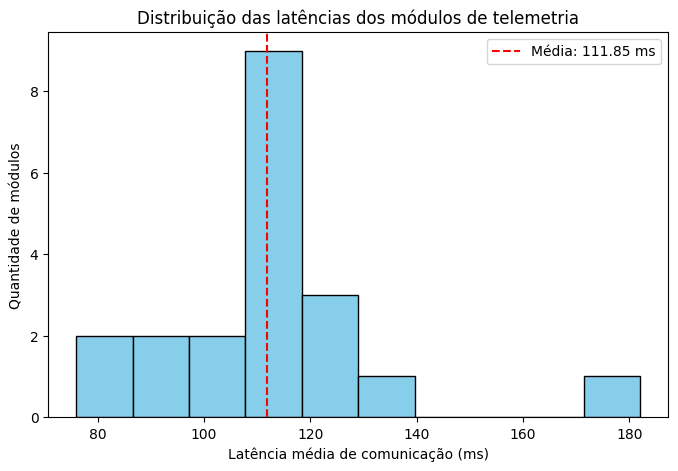

In [13]:
plot_histograma_latencia(dados)

10. Utilize a função `plot_boxplot_latencia()` para criar um boxplot das latências. Identifique visualmente os quartis, a mediana e possíveis valores atípicos (outliers).

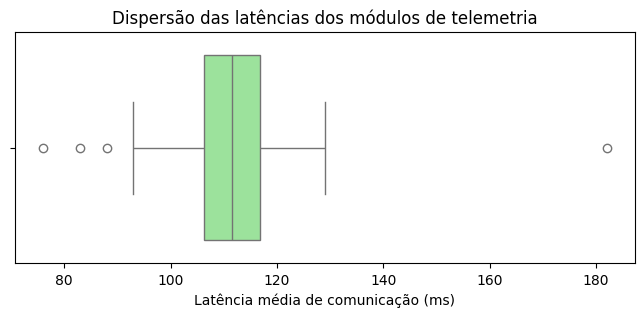

In [14]:
plot_boxplot_latencia(dados)

11. Com base no boxplot, quais módulos podem ser considerados outliers? Explique como essas latências podem orientar a investigação de problemas de comunicação e a validação do requisito de 130 ms.

Resposta: Os módulos 06, 11 e 17 apresentam comunicação mais rápida, o que não significa necessariamente um problema. Já o Módulo 12 ultrapassa o requisito de 130 ms, devendo ser investigado quanto a interferências, sinal fraco ou retransmissões. Assim, 19 dos 20 módulos atendem ao requisito nos testes realizados.